# 01 · FI-2010: com'è fatto un book L2

**FI-2010** (Ntakaris et al., 2018) è un dataset pubblico molto usato in letteratura: dieci giorni di book a 10 livelli per cinque titoli della borsa finlandese, con prezzi normalizzati e un'osservazione ogni 10 eventi. È un dataset **L2**: si vedono i prezzi e i volumi a ogni livello, ma non i singoli ordini. Per un'introduzione al funzionamento dei limit order book si vedano la rassegna di Gould et al. (2013) e il manuale di Bouchaud, Bonart, Donier e Gould (2018).

In questo notebook si controlla la qualità dei dati e si guarda una caratteristica che spiega gran parte dei risultati successivi: **il prezzo resta fermo per la maggior parte del tempo**.

I termini tecnici sono spiegati nel **glossario** in fondo al notebook 06.

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/market_making_tesi").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from market_making_tesi import report as R
from market_making_tesi.report import it, pct
R.setup_plots()
FIGURES = ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
np.random.seed(0)
from market_making_tesi import storage
from market_making_tesi.parsers import load_fi2010_matrix, fi2010_stock_segments
quality = R.load(ROOT, "quality").query("dataset == 'fi2010'")
counts = quality.pivot(index="session", columns="symbol", values="records")
anomalies = int(quality[["ts_decreasing", "crossed", "nonpositive_size", "nonfinite_mid"]].sum().sum())
R.show_box("In breve", [
    f"{it(counts.values.sum())} osservazioni in {counts.size} sessioni (10 giorni × 5 titoli).",
    f"Anomalie trovate (prezzi incrociati, volumi non positivi, valori mancanti): {anomalies}.",
    "Il midpoint resta invariato tra due osservazioni nella maggior parte dei casi (sezione 3).",
])
display(Markdown("**Osservazioni per giorno e titolo**"))
display(counts)

> **In breve**
>
> - 394.337 osservazioni in 50 sessioni (10 giorni × 5 titoli).
> - Anomalie trovate (prezzi incrociati, volumi non positivi, valori mancanti): 0.
> - Il midpoint resta invariato tra due osservazioni nella maggior parte dei casi (sezione 3).

**Osservazioni per giorno e titolo**

symbol,stock1,stock2,stock3,stock4,stock5
session,,,,,
day01,3454,6318,4922,10719,14099
day02,5079,6122,5965,6712,14519
day03,3903,5411,4027,5186,10008
day04,2806,6992,5342,10819,11064
day05,3030,6728,5946,6378,12703
day06,2263,6243,5607,7007,18032
day07,2801,7060,6740,7854,12891
day08,2647,8662,8591,13229,22349
day09,1873,9271,10036,12880,18112


## 1. I cinque titoli sono "incollati" uno dopo l'altro

Ogni file giornaliero contiene i cinque titoli in sequenza, senza una colonna che dica dove finisce uno e inizia l'altro. Se non li si separa, il backtest tratterebbe il passaggio da un titolo all'altro come un salto di prezzo enorme. I confini si riconoscono proprio da questi salti (oltre il 5% del prezzo): le linee tratteggiate nel grafico.

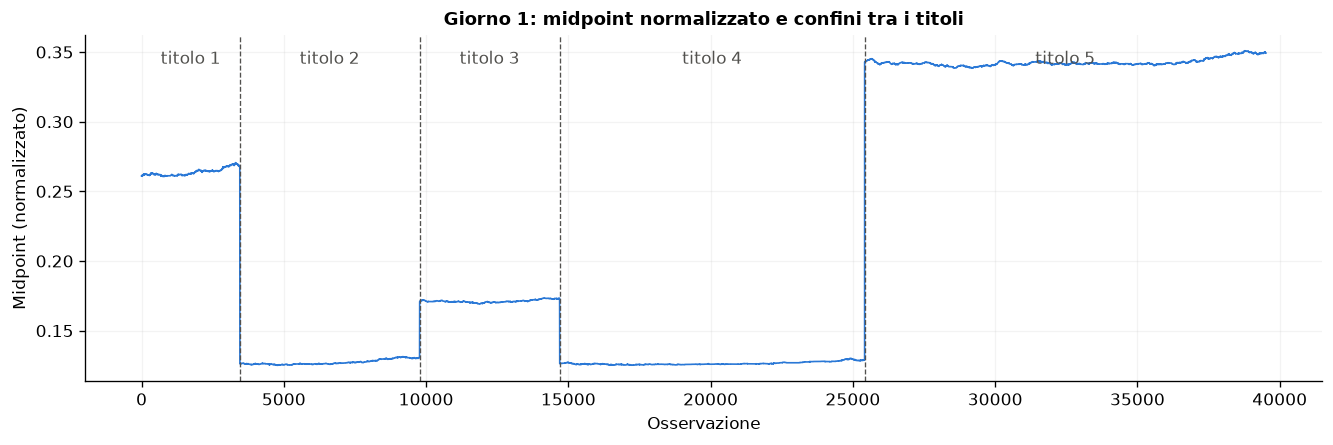

In [2]:
matrix = load_fi2010_matrix(ROOT / "data/raw/fi2010/fi2010_day01.txt")
mid = (matrix[0] + matrix[2]) / 2
bounds = fi2010_stock_segments(matrix)
fig, ax = plt.subplots(figsize=(11, 3.6), layout="constrained")
ax.plot(mid, color=R.COLORS["touch"], linewidth=1)
for start, _ in bounds[1:]:
    ax.axvline(start, color=R.INK, linewidth=0.8, linestyle="--")
for k, (start, stop) in enumerate(bounds, 1):
    ax.text((start + stop) / 2, mid.max(), f"titolo {k}", ha="center", va="top", color=R.INK)
ax.set(title="Giorno 1: midpoint normalizzato e confini tra i titoli", xlabel="Osservazione", ylabel="Midpoint (normalizzato)")
fig.savefig(FIGURES / "fi2010_confini.png", dpi=180, bbox_inches="tight")
plt.show()

## 2. Spread e prezzo fermo

Due grandezze contano per il market making:

* lo **spread** (distanza tra miglior prezzo in vendita e in acquisto), misurato in *tick*, il passo minimo di prezzo: è il guadagno massimo di una coppia di ordini;
* quanto spesso il **midpoint resta invariato**: se il prezzo è fermo, nessuno sta davvero "attraversando" le quote.

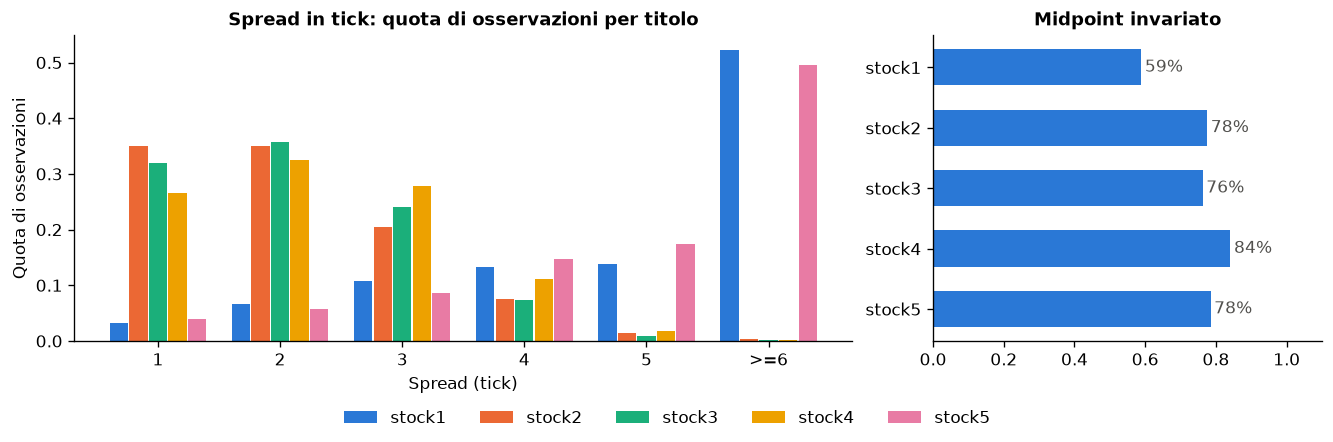

,1,2,3,4,5,>=6
symbol,,,,,,
stock1,3%,7%,11%,13%,14%,52%
stock2,35%,35%,21%,8%,1%,0%
stock3,32%,36%,24%,7%,1%,0%
stock4,27%,33%,28%,11%,2%,0%
stock5,4%,6%,9%,15%,17%,50%


**Come leggerlo.** Il midpoint resta fermo nel 78% dei casi. La regola `touch` (notebook 02) considera eseguito un acquisto quando il best bid è uguale o inferiore alla quota: con il prezzo fermo questo accade di continuo, anche se nessuno ha davvero scambiato. È la ragione principale per cui `touch` sovrastima le esecuzioni.

In [3]:
rows = []
for session, symbol, path in storage.sessions(ROOT / "data/interim", "fi2010", "snapshots"):
    t = pd.read_parquet(path, columns=["bid_px_1", "ask_px_1"])
    rows.append(pd.DataFrame({"symbol": symbol, "spread": t.ask_px_1 - t.bid_px_1,
                              "ret": ((t.bid_px_1 + t.ask_px_1) / 2).diff()}))
eda = pd.concat(rows)
TICK = 0.0001  # passo minimo dei prezzi normalizzati
eda["ticks"] = (eda.spread / TICK).round().clip(upper=6).astype(int)
shares = eda.groupby("symbol").ticks.value_counts(normalize=True).unstack(fill_value=0)
shares.columns = [f"{c}" if c < 6 else ">=6" for c in shares.columns]
still = eda.groupby("symbol").ret.apply(lambda r: (r.dropna() == 0).mean())
STOCK_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), layout="constrained", gridspec_kw={"width_ratios": [2, 1]})
x = np.arange(len(shares.columns))
for i, (symbol, row) in enumerate(shares.iterrows()):
    axes[0].bar(x + (i - 2) * 0.16, row.values, 0.15, color=STOCK_COLORS[i], label=symbol)
axes[0].set_xticks(x, shares.columns)
axes[0].set(title="Spread in tick: quota di osservazioni per titolo", xlabel="Spread (tick)", ylabel="Quota di osservazioni")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=5, frameon=False)
axes[1].barh(still.index[::-1], still.values[::-1], color=R.COLORS["touch"], height=0.6)
for y, v in enumerate(still.values[::-1]):
    axes[1].text(v + 0.01, y, pct(v, 0), va="center", color=R.INK)
axes[1].set(title="Midpoint invariato", xlim=(0, 1.1))
for ax in axes:
    ax.grid(False)
fig.savefig(FIGURES / "fi2010_distribuzioni.png", dpi=180, bbox_inches="tight")
plt.show()
display(shares.style.format("{:.0%}").set_caption("Quota di osservazioni per spread (tick)"))
display(Markdown(
    f"**Come leggerlo.** Il midpoint resta fermo {R.nel((eda.ret == 0).mean(), 0)} dei casi. La regola `touch` (notebook 02) "
    "considera eseguito un acquisto quando il best bid è uguale o inferiore alla quota: con il prezzo fermo questo accade "
    "di continuo, anche se nessuno ha davvero scambiato. È la ragione principale per cui `touch` sovrastima le esecuzioni."))

## 3. Volatilità e regime di bassa volatilità

La strategia opera solo quando la volatilità è bassa. La volatilità a ogni osservazione è la deviazione standard delle variazioni del midpoint nelle ultime *W* osservazioni:

* con una **finestra corta** (W = 20) la stima reagisce subito a uno shock ma è nervosa e accende e spegne la strategia di continuo;
* con una **finestra lunga** (W = 100) è più stabile ma reagisce in ritardo.

La soglia è un percentile della volatilità osservata il giorno 1 (calibrazione). Nel grafico, in grigio, i tratti in cui la volatilità supera la soglia del 75° percentile e la strategia resterebbe ferma.

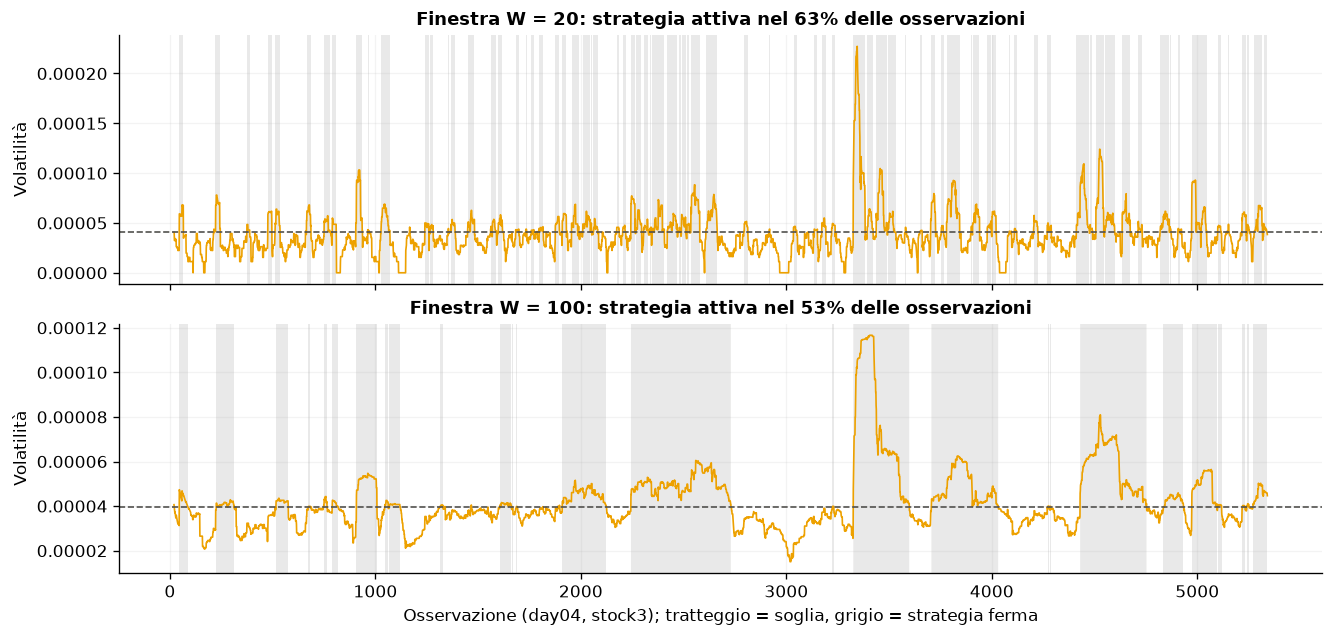

**Come leggerlo.** Con la finestra corta i periodi di sospensione sono molti e brevi; con quella lunga sono pochi e più lunghi. Quale funzioni meglio non si decide a occhio: finestra e soglia vengono scelte in validazione (notebook 02).

In [4]:
cal = R.load(ROOT, "calibration").query("dataset == 'fi2010' and session == 'day01'").set_index("symbol")
session, symbol = "day04", "stock3"
path = next(p for s_, sym, p in storage.sessions(ROOT / "data/interim", "fi2010", "snapshots") if s_ == session and sym == symbol)
t = pd.read_parquet(path, columns=["bid_px_1", "ask_px_1"])
ret = ((t.bid_px_1 + t.ask_px_1) / 2).diff()
fig, axes = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True, layout="constrained")
active = {}
for ax, w in zip(axes, (20, 100)):
    vol = ret.rolling(w, min_periods=min(20, w)).std()
    thr = cal.loc[symbol, f"threshold_w{w}_q75"]
    ax.plot(vol.index, vol, color=R.COLORS["queue"], linewidth=1)
    ax.axhline(thr, color=R.INK, linestyle="--", linewidth=1)
    ax.fill_between(vol.index, 0, 1, where=(vol > thr).to_numpy(), transform=ax.get_xaxis_transform(),
                    color=R.INK, alpha=0.12, linewidth=0, step="post")
    active[w] = (vol.dropna() <= thr).mean()
    ax.set(ylabel="Volatilità", title=f"Finestra W = {w}: strategia attiva {R.nel(active[w], 0)} delle osservazioni")
axes[1].set(xlabel=f"Osservazione ({session}, {symbol}); tratteggio = soglia, grigio = strategia ferma")
fig.savefig(FIGURES / "fi2010_volatilita_finestre.png", dpi=180, bbox_inches="tight")
plt.show()
display(Markdown(
    "**Come leggerlo.** Con la finestra corta i periodi di sospensione sono molti e brevi; con quella lunga sono pochi e "
    "più lunghi. Quale funzioni meglio non si decide a occhio: finestra e soglia vengono scelte in validazione (notebook 02)."))